# 07b · Batch-3 secondary analysis and monitor configuration (phase 7b of 10)
Batch 3 is spent: labels are used for descriptive reporting only. The monitor configuration is built from development data only and frozen (hash-logged) before any batch-3 label is read. No training, no pretrained weights. Writes only inside `outputs/phase7b`.

In [1]:
# S0 setup
SMOKE = False   # True: 8 batch-3 cells, 200 bootstrap draws, outputs/phase7b/smoke/. Never quote smoke results.
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
import sys, json, hashlib, time, platform, warnings, re, math, textwrap, datetime as dt
sys.dont_write_bytecode = True
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import pyarrow.dataset as pds
from scipy import stats
from scipy.signal import lfilter

T0 = time.time()
SEED = 42
DRAWS = 200 if SMOKE else 5000
np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cudnn.deterministic = True
torch.set_float32_matmul_precision("highest")
warnings.filterwarnings("ignore", category=FutureWarning)

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "notebooks").is_dir() and (p / "data").is_dir()), None)
if ROOT is None:
    raise RuntimeError(f"project root not found: no folder in {_cwd} or its parents contains both notebooks/ and data/")
OUT = ROOT / "outputs" / "phase7b" / ("smoke" if SMOKE else "")
OUT.mkdir(parents=True, exist_ok=True)
P7A = ROOT / "outputs" / "phase7a"
LOG_PATH = OUT / "phase7b_log.jsonl"

def sha256_bytes(b): return hashlib.sha256(b).hexdigest()
def sha256_file(p, lf=False):
    b = Path(p).read_bytes()
    return sha256_bytes(b.replace(b"\r\n", b"\n") if lf else b)
def now_utc(): return dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")
def _jd(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (set, tuple)): return list(o)
    if isinstance(o, Path): return str(o)
    raise TypeError(type(o))
def W(path):
    p = Path(path).resolve()
    if p != OUT.resolve() and OUT.resolve() not in p.parents:
        raise PermissionError(f"write refused (outside {OUT}): {p}")
    p.parent.mkdir(parents=True, exist_ok=True)
    return p
def write_text(path, text): W(path).write_text(text, encoding="utf-8", newline="\n")
def write_json(path, obj): write_text(path, json.dumps(obj, indent=2, sort_keys=True, default=_jd) + "\n")

CHECKS, EXTRA = [], {}
class CheckFail(RuntimeError): pass
def dump_report(failed=None):
    n = {k: sum(c["status"] == k for c in CHECKS) for k in ("PASS", "WARN", "FAIL")}
    write_json(OUT / "verification_report.json", dict(created_utc=now_utc(), smoke=SMOKE, failed=failed, summary=n, checks=CHECKS,
                                                      extra=EXTRA, elapsed_s=round(time.time() - T0, 1)))
    return n
def check(name, ok, detail="", warn_only=False):
    ok = bool(ok)
    status = "PASS" if ok else ("WARN" if warn_only else "FAIL")
    CHECKS.append(dict(name=name, status=status, detail=str(detail)))
    print(f"[{status}] {name}" + (f" - {detail}" if str(detail) else ""))
    if status == "FAIL":
        dump_report(failed=name)
        raise CheckFail(f"{name}: {detail}")

TABLES = {}
def show(df, title, name=None, nd=3):
    print(f"\n{title}  (n={len(df)} rows)")
    print(df.to_string(index=False, float_format=lambda v: f"{v:.{nd}f}"))
    if name: TABLES[name] = df
    return df

# append-only log with hash chain (same scheme as 7a)
def _log_lines():
    return [l for l in LOG_PATH.read_text(encoding="utf-8").splitlines() if l.strip()] if LOG_PATH.exists() else []
def log_entries(): return [json.loads(l) for l in _log_lines()]
def log_has(ev): return any(e["event"] == ev for e in log_entries())
def log_append(event, **kw):
    assert event in ("start", "config_frozen", "labels_loaded", "done")
    ls = _log_lines()
    prev = sha256_bytes(ls[-1].encode("utf-8")) if ls else ""
    entry = dict(t_utc=now_utc(), event=event, prev_line_sha256=prev, smoke=SMOKE, **kw)
    with open(W(LOG_PATH), "a", encoding="utf-8", newline="\n") as f:
        f.write(json.dumps(entry, sort_keys=True, default=_jd) + "\n")
    return entry

# environment
print(f"torch {torch.__version__} | python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | SMOKE={SMOKE}")
cuda = torch.cuda.is_available()
if cuda:
    _free, _tot = torch.cuda.mem_get_info()
    _det = f"device {torch.cuda.get_device_name(0)}, free VRAM {_free / 2**30:.2f} of {_tot / 2**30:.2f} GB"
else:
    _det = "torch.cuda.is_available() is False; this notebook needs no GPU"
check("CUDA available", cuda, _det, warn_only=True)
print("ROOT:", ROOT, "| OUT:", OUT)

torch 2.14.1+cu130 | python 3.13.13 | numpy 2.5.4 | pandas 3.1.0 | SMOKE=False
[PASS] CUDA available - device NVIDIA GeForce RTX 3050 6GB Laptop GPU, free VRAM 5.04 of 6.00 GB
ROOT: C:\workstation\3RD YEAR\Battery-Health-Estimation | OUT: C:\workstation\3RD YEAR\Battery-Health-Estimation\outputs\phase7b


In [2]:
# S0 integrity: hashes, lock log, predictions (no labels)
MODEL_FILES = ["M0_W240.npz", "M0_W300.npz", "M0idx_W240.npz", "M0idx_W300.npz"]
FROZEN = {
    "gate_week2":      (ROOT / "outputs/phase4/week2_gate.json", "40df2fb82096e994f8bf7b8084433bb5ca148d3fa92c780461f68c0c4247d901", False),
    "soh_deep_v2":     (ROOT / "src/soh_deep_v2.py", "fc53e37d506ebe51f6e4d71819c4b047de5bc38456669a160183531fbefebea6", True),
    "soh_deep_v3":     (ROOT / "src/soh_deep_v3.py", "9c022dd391193de9c65f2d77b9dcdc5a2e939419596ecb38a55399ffcc06cbbb", True),
    "soh_deep_v4":     (ROOT / "src/soh_deep_v4.py", "2be9ce5ded197b16028079e7d34b550c683f4152b528f55f5064251b146eded4", False),
    "gate_verdict_5b": (ROOT / "outputs/phase5b/gate_verdict.json", "2f59f82a7c7d8940636b55d7fd3397760d4486569d95575c802dbd02df69b1bb", False),
    "frozen_config":   (ROOT / "outputs/phase6b/frozen_config.json", "78b571c7526551c70a01cb709661052ddfb5b4c9783e4eb5babb1c7e11b65fe5", False),
    "preregistration": (P7A / "preregistration.json", "11f9741387cb001ef55aa8459e4857ab70871e89cd03e7cce318043be41c8bce", False),
    "batch3_predictions": (P7A / "batch3_predictions.parquet", "679ec76862de63f2615a710c7fc1f3ca2ec6c01149735bdd909b95ad5a9c7acd", False),
    "batch3_verdict":  (P7A / "batch3_verdict.json", "57a054bdf25243d3b9e0aced2c0c245135da2c769b2d1e635d329b742fc4deb8", False),
    "formal_comparators": (P7A / "formal_comparators.json", "0e1c1daa4839e8b92773c04a866327d308d5a1bda29e9768ca83f3bf91fc2231", False),
    "comparator_reproduction": (P7A / "comparator_reproduction.csv", "2e9bd9d7d9c588aac6ee78f6d1e7f13ae736d2aeb8cccb251368d997627f2688", False),
    "model_M0_W240":    (P7A / "models/M0_W240.npz", "29cd3ec8c5c2113db1d1b3562365461f3045f07b5e3113532f28eeff34c744fe", False),
    "model_M0_W300":    (P7A / "models/M0_W300.npz", "06f63dc6c5a89750d18622099961e875ee1aeb1b65d9afe16b556f0d7cb149c2", False),
    "model_M0idx_W240": (P7A / "models/M0idx_W240.npz", "b7822335aa1c7cb592e4a12e3044c614a3b2616b2a5be5c940b47579862f8e18", False),
    "model_M0idx_W300": (P7A / "models/M0idx_W300.npz", "0e7430ee1586a57b38207ce95e7d73b902b230678a92c0f32a4a704e5c05e99e", False),
}
def verify_frozen(tag):
    res = {}
    for k, (p, h, lf) in FROZEN.items():
        if not p.exists():
            check(f"[{tag}] sha256 {k}", False, f"file missing: {p}")
        got = sha256_file(p, lf)
        res[k] = dict(path=str(p.relative_to(ROOT)), expected=h, got=got, lf_normalised=lf)
        check(f"[{tag}] sha256 {k}", got == h, f"{p.name}: got {got[:16]}... expected {h[:16]}...")
    return res
HASHES_START = verify_frozen("start")

# 7a lock log chain
_ll = P7A / "locked_test_log.jsonl"
if not _ll.exists(): raise FileNotFoundError(f"7a lock log missing: {_ll}")
_lines = [l for l in _ll.read_text(encoding="utf-8").splitlines() if l.strip()]
_ev = [json.loads(l) for l in _lines]
_want = ["preregistration_written", "placeholder_test", "formal_comparators_written", "predictions_written", "unlock", "scored"]
check("7a lock log: 6 events in order", [e["event"] for e in _ev] == _want, f"found {[e['event'] for e in _ev]}")
_chain = [(_ev[i]["prev_line_sha256"] == (sha256_bytes(_lines[i - 1].encode("utf-8")) if i else "")) for i in range(len(_ev))]
check("7a lock log: prev_line_sha256 chain intact", all(_chain), f"{sum(_chain)} of {len(_chain)} links valid")

# predictions (hash-verified above); key checks only, no labels
PRED = pd.read_parquet(P7A / "batch3_predictions.parquet")
print("batch3_predictions columns:", list(PRED.columns), "shape:", PRED.shape)
_need = {"model", "window", "seed", "row_id", "cell_id", "pred_pp"}
check("predictions have the expected columns", _need <= set(PRED.columns), f"columns {list(PRED.columns)}, missing {sorted(_need - set(PRED.columns))}")
WINDOWS = ["W300", "W240"]
_ser = PRED.groupby(["model", "window", "seed"]).size()
check("predictions: 1,375,504 rows", len(PRED) == 1_375_504, f"{len(PRED):,} rows")
check("predictions: 34 series", len(_ser) == 34, f"{len(_ser)} series: {sorted(set(PRED.model.astype(str)))}")
check("predictions: 40,456 rows per series", (_ser == 40456).all(), f"per-series rows min {_ser.min()}, max {_ser.max()}")
check("predictions: no duplicate keys", not PRED.duplicated(["model", "window", "seed", "row_id"]).any(), f"{PRED.row_id.nunique():,} unique row_ids")
check("predictions: no NaN", PRED.pred_pp.notna().all(), f"{int(PRED.pred_pp.isna().sum())} NaN")
check("predictions: windows are W300 and W240", set(PRED.window.astype(str)) == set(WINDOWS), f"windows {sorted(set(PRED.window.astype(str)))}")
LAB = {"M0": "M0", "M0idx": "M0+idx", "B0b": "B0b", "B3": "B3", "B3r": "B3r", "B4": "B4", "B4r": "B4r", "B4ridx": "B4r+idx", "B1": "B1", "AVG": "avg(M0,B4r)"}
check("predictions: all model names known", set(PRED.model.astype(str)) <= set(LAB), f"unknown {sorted(set(PRED.model.astype(str)) - set(LAB))}")
log_append("start", hashes={k: v["got"] for k, v in HASHES_START.items()}, lock_log_events=len(_ev), prediction_rows=len(PRED))

[PASS] [start] sha256 gate_week2 - week2_gate.json: got 40df2fb82096e994... expected 40df2fb82096e994...
[PASS] [start] sha256 soh_deep_v2 - soh_deep_v2.py: got fc53e37d506ebe51... expected fc53e37d506ebe51...
[PASS] [start] sha256 soh_deep_v3 - soh_deep_v3.py: got 9c022dd391193de9... expected 9c022dd391193de9...
[PASS] [start] sha256 soh_deep_v4 - soh_deep_v4.py: got 2be9ce5ded197b16... expected 2be9ce5ded197b16...
[PASS] [start] sha256 gate_verdict_5b - gate_verdict.json: got 2f59f82a7c7d8940... expected 2f59f82a7c7d8940...
[PASS] [start] sha256 frozen_config - frozen_config.json: got 78b571c7526551c7... expected 78b571c7526551c7...
[PASS] [start] sha256 preregistration - preregistration.json: got 11f9741387cb001e... expected 11f9741387cb001e...
[PASS] [start] sha256 batch3_predictions - batch3_predictions.parquet: got 679ec76862de63f2... expected 679ec76862de63f2...
[PASS] [start] sha256 batch3_verdict - batch3_verdict.json: got 57a054bdf25243d3... expected 57a054bdf25243d3...
[PASS

{'t_utc': '2026-11-05T03:30:09+00:00',
 'event': 'start',
 'prev_line_sha256': '4ee2f6b72231992a643315682fab54842a87d4db99cc38eee048365bd7b4f600',
 'smoke': False,
 'hashes': {'gate_week2': '40df2fb82096e994f8bf7b8084433bb5ca148d3fa92c780461f68c0c4247d901',
  'soh_deep_v2': 'fc53e37d506ebe51f6e4d71819c4b047de5bc38456669a160183531fbefebea6',
  'soh_deep_v3': '9c022dd391193de9c65f2d77b9dcdc5a2e939419596ecb38a55399ffcc06cbbb',
  'soh_deep_v4': '2be9ce5ded197b16028079e7d34b550c683f4152b528f55f5064251b146eded4',
  'gate_verdict_5b': '2f59f82a7c7d8940636b55d7fd3397760d4486569d95575c802dbd02df69b1bb',
  'frozen_config': '78b571c7526551c70a01cb709661052ddfb5b4c9783e4eb5babb1c7e11b65fe5',
  'preregistration': '11f9741387cb001ef55aa8459e4857ab70871e89cd03e7cce318043be41c8bce',
  'batch3_predictions': '679ec76862de63f2615a710c7fc1f3ca2ec6c01149735bdd909b95ad5a9c7acd',
  'batch3_verdict': '57a054bdf25243d3b9e0aced2c0c245135da2c769b2d1e635d329b742fc4deb8',
  'formal_comparators': '0e1c1daa4839e8b92

In [3]:
# S1 inputs (development data only)
def find_one(name, dirs):
    for d in dirs:
        if (d / name).exists(): return d / name
    hits = [p for p in ROOT.rglob(name) if ".venv" not in p.parts]
    if hits: return hits[0]
    raise FileNotFoundError(f"{name} not found under {[str(d) for d in dirs]} or anywhere below {ROOT}")
DP = ROOT / "data" / "processed"
for nm in ("cycles_table.parquet", "qdlin_f32.npy", "t_knots_f32.npy", "qref_f32.npy"):
    p = find_one(nm, [DP]); print("found", p.relative_to(ROOT))
print("qdlin shape", tuple(np.load(find_one("qdlin_f32.npy", [DP]), mmap_mode="r").shape), "| qref shape", tuple(np.load(find_one("qref_f32.npy", [DP])).shape),
      "| cycles_table columns", list(pds.dataset(str(find_one("cycles_table.parquet", [DP]))).schema.names))
check("qdlin is 104,971 x 1000", tuple(np.load(find_one("qdlin_f32.npy", [DP]), mmap_mode="r").shape) == (104971, 1000), "see print above")

REG_PATH = find_one("cell_registry_final.csv", [DP, ROOT / "outputs/phase3"])
REG = pd.read_csv(REG_PATH)
print("registry", REG_PATH.relative_to(ROOT), "columns", list(REG.columns), "shape", REG.shape)
for c in ("cell_id", "policy_norm", "batch"):
    check(f"registry has column {c}", c in REG.columns, f"columns {list(REG.columns)}")
LIFECOL = next((c for c in ("cycle_life_field", "cycle_life", "life", "cycle_life_final") if c in REG.columns), None)
check("registry has a cycle-life column", LIFECOL is not None, f"using '{LIFECOL}' (spec: EOL = the cycle_life field)")
_stitch_cols = [c for c in ("stitched_into", "has_continuation", "continuation_cell") if c in REG.columns] or [c for c in REG.columns if "stitch" in c.lower()]
_NO = ("", "nan", "none", "false", "0", "0.0", "<na>", "nat")
def _truthy(s): return s.map(lambda v: (v is not None) and str(v).strip().lower() not in _NO).astype(bool)
_st = np.logical_or.reduce([_truthy(REG[c]).values for c in _stitch_cols]) if _stitch_cols else np.zeros(len(REG), bool)
STITCHED = set(REG.loc[_st, "cell_id"])
check("registry stitched flag found", bool(_stitch_cols), f"columns {_stitch_cols}; {len(STITCHED)} stitched cells (of {len(REG)} registry rows)", warn_only=True)
LIFE = dict(zip(REG.cell_id, REG[LIFECOL].astype(float)))
POLICY = dict(zip(REG.cell_id, REG.policy_norm))

LAB_CANDS = sorted(DP.glob("labels_table*.parquet")) or sorted((ROOT / "outputs/phase3").glob("labels_table*.parquet"))
if not LAB_CANDS: raise FileNotFoundError("no labels_table*.parquet under data/processed or outputs/phase3")
LABELS_PATH = next((c for c in LAB_CANDS if c.stem == "labels_table_v2"), LAB_CANDS[-1])
_ds = pds.dataset(str(LABELS_PATH))
print("labels table", LABELS_PATH.relative_to(ROOT), "columns", _ds.schema.names)
check("label table has needed columns", {"row_id", "cell_id", "batch", "cycle_number", "soh_nom", "scored2"} <= set(_ds.schema.names), f"columns {_ds.schema.names}")
def _bnum(v):
    if isinstance(v, (int, float, np.integer, np.floating)): return int(v)
    m = re.search(r"\d+", str(v)); return int(m.group()) if m else -1
_bcol = _ds.to_table(columns=["batch"]).column("batch").to_pandas()
B3VALS = [v.item() if hasattr(v, "item") else v for v in pd.unique(_bcol) if _bnum(v) == 3]
check("batch-3 value found in labels.batch", len(B3VALS) >= 1, f"batch values {list(pd.unique(_bcol))}")

LABEL_LOG, LABELS_UNLOCKED = [], False
def read_labels(columns, subset):
    assert subset in ("dev", "b3", "all")
    has_y = "soh_nom" in columns
    if has_y and subset != "dev" and not LABELS_UNLOCKED:
        raise PermissionError("batch-3 labels are locked until config_frozen is logged")
    expr = (~pds.field("batch").isin(B3VALS)) if subset == "dev" else (pds.field("batch").isin(B3VALS) if subset == "b3" else None)
    t = _ds.to_table(columns=list(columns), filter=expr)
    LABEL_LOG.append(dict(t_utc=now_utc(), columns=list(columns), subset=subset, b3_label=bool(has_y and subset != "dev"), n=t.num_rows,
                          config_frozen_logged=log_has("config_frozen")))
    return t.to_pandas()

lab0 = read_labels(["row_id", "cell_id", "batch", "cycle_number", "scored2"], "all")
check("labels: row_id equals row position", np.array_equal(lab0.row_id.values, np.arange(len(lab0))), f"{len(lab0):,} rows")
lab0["batch_i"] = lab0.batch.map(_bnum); lab0["scored2"] = lab0.scored2.astype(bool)
LAB_IDX = lab0.set_index("row_id")
_ld = read_labels(["row_id", "soh_nom"], "dev")
YDEV = pd.Series(100.0 * _ld.soh_nom.to_numpy(np.float64), index=_ld.row_id.to_numpy()); del _ld
check("development labels read without batch 3", not YDEV.index.isin(lab0.loc[lab0.batch_i == 3, "row_id"]).any(), f"{len(YDEV):,} development-side rows")

# development out-of-fold predictions (phase 5b final_*.parquet)
_ff = sorted((ROOT / "outputs/phase5b/cache").glob("final_*.parquet"))
if not _ff: raise FileNotFoundError("no outputs/phase5b/cache/final_*.parquet")
FIN = pd.concat([pd.read_parquet(f) for f in _ff], ignore_index=True)
print("5b final tables:", [f.name for f in _ff], "| columns", list(FIN.columns), "| shape", FIN.shape)
check("5b columns present", {"window", "model", "repeat", "outer_fold", "seed", "row_id", "cell_id", "pred_pp"} <= set(FIN.columns), f"columns {list(FIN.columns)}")
print("5b models:", sorted(FIN.model.astype(str).unique()), "windows:", sorted(FIN.window.astype(str).unique()), "repeats:", sorted(FIN.repeat.unique()))
check("5b contains model M0 for both windows", all(((FIN.model.astype(str) == "M0") & (FIN.window.astype(str) == w)).any() for w in WINDOWS),
      f"models {sorted(FIN.model.astype(str).unique())}")

def build_dev(w):
    f = FIN[(FIN.model.astype(str) == "M0") & (FIN.window.astype(str) == w)]
    g = f.groupby(["repeat", "row_id"]).agg(pred=("pred_pp", "mean"), nseed=("seed", "nunique"), cell_id=("cell_id", "first")).reset_index()
    g["cycle"] = LAB_IDX.loc[g.row_id, "cycle_number"].to_numpy().astype(float)
    g["scored"] = LAB_IDX.loc[g.row_id, "scored2"].to_numpy()
    g = g[g.scored].copy()
    g["y"] = YDEV.reindex(g.row_id).to_numpy()
    g["life"] = g.cell_id.map(LIFE)
    g["stitched"] = g.cell_id.isin(STITCHED)
    check(f"{w} dev OOF: finite y, pred, life", np.isfinite(g[["y", "pred", "life"]].to_numpy()).all(), f"{len(g):,} rows")
    return g.sort_values(["repeat", "cell_id", "cycle", "row_id"]).reset_index(drop=True)
DEV = {w: build_dev(w) for w in WINDOWS}
DEV_CELLS = sorted(DEV["W300"].cell_id.unique())
B3_ALL = sorted(PRED.cell_id.unique())
for w in WINDOWS:
    d = DEV[w]
    check(f"{w} dev OOF: 84 cells, 5 seeds per row", d.cell_id.nunique() == 84 and (d.nseed == 5).all(),
          f"{d.cell_id.nunique()} cells, {d.repeat.nunique()} repeats, {len(d):,} rows, seeds/row min {d.nseed.min()} max {d.nseed.max()}")
    print(f"  {w}: rows per repeat {d.groupby('repeat').size().to_dict()}")
check("dev and batch-3 cells are disjoint; all in registry", not (set(DEV_CELLS) & set(B3_ALL)) and all(c in LIFE for c in DEV_CELLS + B3_ALL),
      f"{len(DEV_CELLS)} dev, {len(B3_ALL)} batch-3")
check("batch-3 cells are batch 3 and dev cells are not", set(lab0.loc[lab0.cell_id.isin(B3_ALL), "batch_i"]) == {3} and 3 not in set(lab0.loc[lab0.cell_id.isin(DEV_CELLS), "batch_i"]),
      f"batch values dev {sorted(set(lab0.loc[lab0.cell_id.isin(DEV_CELLS), 'batch_i']))}")
DEV_POLICIES = {POLICY[c] for c in DEV_CELLS}
SHARED_B3 = sorted(c for c in B3_ALL if POLICY[c] in DEV_POLICIES)
N_DEV_LONG = sum(LIFE[c] > 1434 for c in DEV_CELLS)
print(f"development cells with life > 1,434 cycles: {N_DEV_LONG} of {len(DEV_CELLS)}")
print(f"batch-3 cells sharing a policy with development ({len(SHARED_B3)}):", {c: POLICY[c] for c in SHARED_B3})

# optional cross-check against phase 6a ensemble arrays (informational)
_ea = ROOT / "outputs/phase6a/cache/ensemble_arrays.npz"
if _ea.exists():
    _z = np.load(_ea, allow_pickle=True)
    print("ensemble_arrays.npz keys/shapes:", {k: tuple(_z[k].shape) for k in _z.files})
    EXTRA["ensemble_arrays_keys"] = {k: list(_z[k].shape) for k in _z.files}
else:
    check("6a ensemble_arrays.npz present", False, f"missing {_ea}; 5b out-of-fold predictions are used", warn_only=True)

found data\processed\cycles_table.parquet
found data\processed\qdlin_f32.npy
found data\processed\t_knots_f32.npy
found data\processed\qref_f32.npy
qdlin shape (104971, 1000) | qref shape (129, 1000) | cycles_table columns ['row_id', 'cell_id', 'batch', 'idx', 'status', 'pos', 'cycle_number', 'segment', 'src_cell', 'pos_src', 'cycle_number_src', 'placeholder', 'len_mismatch', 'qd_sum', 'qc_sum', 'ir', 'chargetime', 'n_samples', 'qd_end', 'qc_end', 'i_dis_median', 'qd_at_v35', 'qd_at_vlow', 'qd_cv_tail', 'win_cap', 't_dis_start', 'qdlin_len', 'flag_placeholder', 'flag_qdlin_bad', 'flag_diag_suspect', 'flag_ir_nonpos', 'flag_qd_mismatch', 'flag_qdqc_gap', 'flag_qd_spike']
[PASS] qdlin is 104,971 x 1000 - see print above
registry data\processed\cell_registry_final.csv columns ['cell_id', 'batch', 'idx', 'status', 'stitched_into', 'has_continuation', 'continuation_cell', 'policy_str', 'policy_norm', 'cycle_life_field', 'n_cycles', 'cycle_life_final', 'qd_last', 'reached_eol_in_data', 'n_po

In [4]:
# S1a EMA alpha (development only)
ALPHAS = [0.2, 0.3, 0.5]
def ema_col(df, a, keys=("repeat", "cell_id")):
    out = np.empty(len(df)); p = df.pred.to_numpy()
    for _, ix in df.groupby(list(keys), sort=False).indices.items():
        out[ix] = lfilter([a], [1, -(1 - a)], p[ix], zi=[(1 - a) * p[ix][0]])[0]
    return out
def macro_mae(df, col):
    return float((df.assign(ae=np.abs(df[col] - df.y)).groupby(["repeat", "cell_id"]).ae.mean().groupby("repeat").mean()).mean())
EMA_ROWS, ALPHA = [], {}
for w in WINDOWS:
    d = DEV[w]; r = {"raw": macro_mae(d, "pred")}
    for a in ALPHAS:
        d[f"ema{a}"] = ema_col(d, a); r[a] = macro_mae(d, f"ema{a}")
    ALPHA[w] = min(ALPHAS, key=lambda a: r[a])
    d["ema"] = d[f"ema{ALPHA[w]}"]
    for k, v in r.items():
        EMA_ROWS.append(dict(window=w, series="raw" if k == "raw" else f"EMA alpha={k}", dev_oof_cell_macro_mae_pp=v, chosen=(k == ALPHA[w])))
show(pd.DataFrame(EMA_ROWS), "EMA alpha selection, development OOF M0 ensemble mean (mean over 3 repeats of cell-macro MAE)", "ema_selection.csv", 4)
for w in WINDOWS: print(f"chosen alpha {w}: {ALPHA[w]}")


EMA alpha selection, development OOF M0 ensemble mean (mean over 3 repeats of cell-macro MAE)  (n=8 rows)
window        series  dev_oof_cell_macro_mae_pp  chosen
  W300           raw                     0.8360   False
  W300 EMA alpha=0.2                     0.8168   False
  W300 EMA alpha=0.3                     0.8160    True
  W300 EMA alpha=0.5                     0.8207   False
  W240           raw                     0.5301   False
  W240 EMA alpha=0.2                     0.5288   False
  W240 EMA alpha=0.3                     0.5211    True
  W240 EMA alpha=0.5                     0.5218   False
chosen alpha W300: 0.3
chosen alpha W240: 0.3


In [5]:
# S1b conformal tables (development only)
def cquantile(x, q):
    n = len(x); k = int(np.ceil((n + 1) * q)); return float(np.sort(x)[min(k, n) - 1])
def wquantile(x, w, q):
    o = np.argsort(x, kind="stable"); cw = np.cumsum(w[o]); cw = cw / cw[-1]
    return float(x[o][min(int(np.searchsorted(cw, q, side="left")), len(x) - 1)])
def find_bin_edges():
    """Reuse a stored phase 6a/6b bin definition if one can be found in a json file, else None."""
    hits = {}
    def walk(o, path, f):
        if isinstance(o, dict):
            for k, v in o.items(): walk(v, path + [str(k)], f)
        elif isinstance(o, list) and len(o) >= 3 and all(isinstance(x, (int, float)) for x in o) and any(re.search(r"bin|edge", p, re.I) for p in path):
            for w in WINDOWS:
                if any(w in p for p in path): hits[w] = (o, f"{f.relative_to(ROOT)}:{'/'.join(path)}")
    for d in (ROOT / "outputs/phase6a", ROOT / "outputs/phase6b"):
        for f in sorted(d.rglob("*.json")):
            try: walk(json.loads(f.read_text(encoding="utf-8")), [], f)
            except Exception: pass
    return hits
STORED_BINS = find_bin_edges()
print("stored 6a/6b bin definitions found:", {w: v[1] for w, v in STORED_BINS.items()} or "none")
def make_edges(pred, cell, stored=None, min_cells=12, nbins=10):
    inner = sorted({float(e) for e in stored if pred.min() < e < pred.max()}) if stored else np.unique(np.quantile(pred, np.arange(1, nbins) / nbins)).tolist()
    while True:
        b = np.searchsorted(inner, pred, side="right"); nb = len(inner) + 1
        nc = [len(np.unique(cell[b == k])) for k in range(nb)]
        bad = [k for k in range(nb) if nc[k] < min_cells]
        if not bad or nb == 1: return inner
        k = min(bad, key=lambda j: nc[j])
        nbr = 1 if k == 0 else (k - 1 if k == nb - 1 else (k - 1 if nc[k - 1] <= nc[k + 1] else k + 1))
        inner.pop(min(k, nbr))
def conf_table(pred, y, cell, inner, cov=0.90):
    b = np.searchsorted(inner, pred, side="right"); ar, ov = np.abs(y - pred), pred - y; rows = []
    for k in range(len(inner) + 1):
        m = b == k; _, inv, cnt = np.unique(cell[m], return_inverse=True, return_counts=True); wt = 1.0 / cnt[inv]
        rows.append(dict(bin=k, pred_lo=None if k == 0 else inner[k - 1], pred_hi=None if k == len(inner) else inner[k], n_rows=int(m.sum()), n_cells=int(len(cnt)),
                         q2_pooled=cquantile(ar[m], cov), q2_cellbal=wquantile(ar[m], wt, cov), ql_pooled=cquantile(ov[m], cov), ql_cellbal=wquantile(ov[m], wt, cov)))
    return dict(inner_edges=list(inner), coverage=cov, bins=rows)
def conf_apply(tab, pred, kind="pooled"):
    b = np.searchsorted(tab["inner_edges"], pred, side="right")
    q2 = np.array([r[f"q2_{kind}"] for r in tab["bins"]])[b]; ql = np.array([r[f"ql_{kind}"] for r in tab["bins"]])[b]
    return pred - q2, pred + q2, pred - ql, q2
CONF, BIN_SRC = {}, {}
for w in WINDOWS:
    CONF[w] = {}
    stored = STORED_BINS[w][0] if w in STORED_BINS else None
    BIN_SRC[w] = STORED_BINS[w][1] if stored else "10 equal-count bins on development OOF predicted SOH, bins with fewer than 12 cells merged (6a/6b bin definition not found)"
    for s in ("raw", "ema"):
        col = "pred" if s == "raw" else "ema"; d = DEV[w]
        inner = make_edges(d[col].to_numpy(), d.cell_id.to_numpy(), stored)
        CONF[w][s] = conf_table(d[col].to_numpy(), d.y.to_numpy(), d.cell_id.to_numpy(), inner)
    print(f"{w} bin definition: {BIN_SRC[w]}")
    t = pd.DataFrame(CONF[w]["raw"]["bins"]); show(t, f"{w} conformal table, raw M0 (calibration rows {int(t.n_rows.sum()):,})", f"conformal_{w}_raw.csv")
    t = pd.DataFrame(CONF[w]["ema"]["bins"]); show(t, f"{w} conformal table, EMA alpha={ALPHA[w]} (calibration rows {int(t.n_rows.sum()):,})", f"conformal_{w}_ema.csv")

stored 6a/6b bin definitions found: none
W300 bin definition: 10 equal-count bins on development OOF predicted SOH, bins with fewer than 12 cells merged (6a/6b bin definition not found)

W300 conformal table, raw M0 (calibration rows 167,889)  (n=10 rows)
 bin  pred_lo  pred_hi  n_rows  n_cells  q2_pooled  q2_cellbal  ql_pooled  ql_cellbal
   0      NaN   87.865   16789       84      2.745       3.629      2.493       3.571
   1   87.865   92.128   16789       84      4.608       3.131      4.591       3.082
   2   92.128   94.403   16789       84      3.085       2.786      3.063       2.768
   3   94.403   95.617   16789       84      3.916       2.219      3.916       2.208
   4   95.617   96.429   16788       83      3.506       1.771      3.506       1.762
   5   96.429   97.007   16789       81      3.467       1.483      3.467       1.479
   6   97.007   97.448   16789       81      2.960       0.983      2.960       0.956
   7   97.448   97.811   16789       76      2.253      

In [6]:
# S1c parity gate, monitor_config.json (write-once), expectations, log config_frozen
def macro_cov(d, lo, hi):
    ins = ((d.y.to_numpy() >= lo) & (d.y.to_numpy() <= hi)).astype(float)
    return float(pd.Series(ins).groupby([d.repeat.to_numpy(), d.cell_id.to_numpy()]).mean().groupby(level=0).mean().mean())
PARITY_REF = {"W300": 0.946, "W240": 0.892}; PARITY = {}
for w in WINDOWS:
    lo, hi, _, _ = conf_apply(CONF[w]["raw"], DEV[w].pred.to_numpy())
    obs = macro_cov(DEV[w], lo, hi); PARITY[w] = dict(observed=obs, reference_6b=PARITY_REF[w], abs_diff=abs(obs - PARITY_REF[w]))
    check(f"parity gate {w}: dev macro coverage vs 6b", abs(obs - PARITY_REF[w]) <= 0.02,
          f"observed {obs:.4f} vs 6b {PARITY_REF[w]:.3f} (abs diff {abs(obs - PARITY_REF[w]):.4f}, tolerance 0.02); own numbers are used", warn_only=True)

# window slices read from the frozen helper module when importable
sys.path.insert(0, str(ROOT / "src")); _imp_ok = True
try:
    import soh_common as sc
    I_CLOSE = {"W300": int(sc.grid_index(3.00)), "W240": int(sc.grid_index(2.40))}; SLICE_SRC = "soh_common.grid_index (frozen module)"
except Exception as e:
    _imp_ok = False; I_CLOSE = {"W300": 333, "W240": 733}; SLICE_SRC = f"task statement (soh_common import failed: {type(e).__name__}: {e})"
check("window closing indices equal 333 / 733", I_CLOSE == {"W300": 333, "W240": 733}, f"{I_CLOSE} from {SLICE_SRC}", warn_only=not _imp_ok)

MODELS_CFG = {k.replace("model_", ""): dict(file=str(FROZEN[k][0].relative_to(ROOT)), sha256=sha256_file(FROZEN[k][0])) for k in FROZEN if k.startswith("model_")}
CFG = dict(
    name="Phase 7b monitor configuration", statement="built from development data only",
    built_from="84 development cells (batches 1+2); out-of-fold M0 ensemble-mean predictions from phase 5b; no batch-3 label or result used",
    windows={w: dict(grid="1000-point voltage grid, 3.5 V down to 2.0 V", start_index=0, end_index_inclusive=I_CLOSE[w], width=I_CLOSE[w] + 1,
                     close_voltage={"W300": 3.00, "W240": 2.40}[w], role={"W300": "headline", "W240": "companion, deployed"}[w], source=SLICE_SRC) for w in WINDOWS},
    reference_cycles="reference cycles per rule D15 (normally cycles 8-12); DeltaQ(V) is referenced to the cell's own early curve",
    scoring_start="normally cycle 20 (last reference cycle + 8); scored cycles <= end of life (EOL = cycle_life field); masked rows excluded",
    q0_definition="Q0 = median discharge capacity QD of the reference cycles", label="soh_nom = QD / 1.1 Ah, in percentage points (pp); bias = pred - y",
    ema=dict(alphas_tested=ALPHAS, chosen=ALPHA, causal=True, initialisation="first scored estimate (no warm-up)", selection="lowest pooled development OOF cell-macro MAE of the smoothed M0 ensemble mean",
             dev_oof_cell_macro_mae_pp={f"{r['window']}|{r['series']}": r["dev_oof_cell_macro_mae_pp"] for r in EMA_ROWS}),
    conformal=dict(coverage=0.90, kind="split conformal calibrated on development OOF M0 predictions, binned by PREDICTED SOH (causal)", bin_definition=BIN_SRC,
                   primary="quantile pooled over rows (q2_pooled two-sided half-width, ql_pooled one-sided over-estimation margin)", sensitivity="cell-balanced weights (q2_cellbal, ql_cellbal)",
                   lower_bound="lower = estimate - ql[bin(estimate)]", interval="estimate +/- q2[bin(estimate)]", tables=CONF, parity_gate=PARITY),
    alert_rules=dict(warning_85=dict(rule="A", fires_when="point estimate <= 85.0 (EMA series primary, raw reported)"),
                     eol_80=dict(rule="B", fires_when="conformal one-sided lower bound <= 80.0", comparison="rule A: point estimate <= 80.0"),
                     true_crossing="first scored cycle with y <= threshold + 1e-9", eol="cycle_life field",
                     metrics="missed = never fires by EOL (right-censored: later detections count as missed); early alarm = fires > 5% of life before the true crossing"),
    models=dict(deployed=dict(model="M0", window="W240", **MODELS_CFG["M0_W240"], note="no cycle index, from-scratch, no pretrained weights"),
                experimental=dict(model="M0+idx", window="W240", **MODELS_CFG["M0idx_W240"], note="EXPERIMENTAL: adds log1p(cycle_number)"), all_files=MODELS_CFG),
    frozen_reference_hashes={k: v["got"] for k, v in HASHES_START.items()})
CFG_PATH = OUT / "monitor_config.json"
_cfg_txt = json.dumps(CFG, indent=2, sort_keys=True, default=_jd) + "\n"
if CFG_PATH.exists():
    check("monitor_config.json already exists; recomputed config identical (write-once)", CFG_PATH.read_text(encoding="utf-8") == _cfg_txt, "recomputed development-only config differs from the frozen file")
else:
    with open(W(CFG_PATH), "x", encoding="utf-8", newline="\n") as f: f.write(_cfg_txt)
CFG_SHA = sha256_file(CFG_PATH)

# expectations, written to file BEFORE any batch-3 label is read (S7 compares them later)
EXPECT = {
    "H1": "The policy-cluster bootstrap interval for M0 - B4 is wider than the cell-level interval at both windows; it may include zero at W300 and is less likely to at W240.",
    "H2": "Conformal macro coverage on batch 3 is at least 0.90 at both windows, with misses concentrated in cells above 1,434 cycles.",
    "H3": "The 85% rule-A warning has a median delay within +/-3% of life.",
    "H4": "Spearman correlation of per-cell M0 bias with life is positive and significant at W300 and not significant at W240."}
EXP_PATH = OUT / "expectations.json"
_exp_txt = json.dumps(EXPECT, indent=2, sort_keys=True) + "\n"
if EXP_PATH.exists(): check("expectations file unchanged since first run", EXP_PATH.read_text(encoding="utf-8") == _exp_txt, "expectation text differs from the stored file")
else:
    with open(W(EXP_PATH), "x", encoding="utf-8", newline="\n") as f: f.write(_exp_txt)
EXP_SHA = sha256_file(EXP_PATH)
check("no batch-3 label read before config_frozen", not any(r["b3_label"] for r in LABEL_LOG), f"{len(LABEL_LOG)} label reads so far, batch-3 label reads {sum(r['b3_label'] for r in LABEL_LOG)}")
if not log_has("config_frozen"):
    log_append("config_frozen", monitor_config_sha256=CFG_SHA, expectations_sha256=EXP_SHA, alpha=ALPHA)
else:
    _e = [e for e in log_entries() if e["event"] == "config_frozen"][0]
    check("monitor_config.json matches the logged config_frozen hash", _e["monitor_config_sha256"] == CFG_SHA, f"logged {_e['monitor_config_sha256'][:16]}..., file {CFG_SHA[:16]}...")
print("monitor_config.json sha256:", CFG_SHA)
print("\nS7 EXPECTATIONS (fixed before batch-3 labels are loaded):")
for k, v in EXPECT.items(): print(f"  {k}: {v}")

[PASS] parity gate W300: dev macro coverage vs 6b - observed 0.9579 vs 6b 0.946 (abs diff 0.0119, tolerance 0.02); own numbers are used
[PASS] parity gate W240: dev macro coverage vs 6b - observed 0.8964 vs 6b 0.892 (abs diff 0.0044, tolerance 0.02); own numbers are used
[PASS] window closing indices equal 333 / 733 - {'W300': 333, 'W240': 733} from soh_common.grid_index (frozen module)
[PASS] no batch-3 label read before config_frozen - 2 label reads so far, batch-3 label reads 0
monitor_config.json sha256: 638b6c3a6ad31c699fb77a22eb9fae72b571d6dc21ee65a73b41e849d7acb4b2

S7 EXPECTATIONS (fixed before batch-3 labels are loaded):
  H1: The policy-cluster bootstrap interval for M0 - B4 is wider than the cell-level interval at both windows; it may include zero at W300 and is less likely to at W240.
  H2: Conformal macro coverage on batch 3 is at least 0.90 at both windows, with misses concentrated in cells above 1,434 cycles.
  H3: The 85% rule-A warning has a median delay within +/-3% o

In [7]:
# unlock batch-3 labels (only now)
check("config_frozen is in the log before labels are read", log_has("config_frozen"), f"log events {[e['event'] for e in log_entries()]}")
LABELS_UNLOCKED = True
B3C = list(B3_ALL)
if SMOKE:
    _o = sorted(B3_ALL, key=lambda c: LIFE[c]); B3C = sorted(_o[int(i)] for i in np.linspace(0, len(_o) - 1, 8))
    print("SMOKE: 8 batch-3 cells", B3C)
B3C_SET = set(B3C)
B3R = lab0[lab0.scored2 & lab0.cell_id.isin(B3C_SET)].sort_values(["cell_id", "cycle_number", "row_id"]).reset_index(drop=True)
_lb = read_labels(["row_id", "soh_nom"], "b3")
_yb = pd.Series(100.0 * _lb.soh_nom.to_numpy(np.float64), index=_lb.row_id.to_numpy()); del _lb
Y_B3 = _yb.reindex(B3R.row_id).to_numpy(); B3_RID = B3R.row_id.to_numpy()
check("batch-3 labels complete", np.isfinite(Y_B3).all(), f"{len(Y_B3):,} rows, {len(B3C)} cells")
check("batch-3 label read happened after config_frozen", all(r["config_frozen_logged"] for r in LABEL_LOG if r["b3_label"]) and sum(r["b3_label"] for r in LABEL_LOG) == 1,
      f"batch-3 label reads {sum(r['b3_label'] for r in LABEL_LOG)}")
log_append("labels_loaded", rows=int(len(Y_B3)), cells=len(B3C), monitor_config_sha256=CFG_SHA)
PREDX = PRED[PRED.cell_id.isin(B3C_SET)]
check("score rows equal prediction rows", set(B3_RID) == set(PREDX.row_id.unique()), f"{len(set(B3_RID)):,} label rows vs {PREDX.row_id.nunique():,} prediction rows")
PR = {}
for (m, w), g in PREDX.groupby(["model", "window"]):
    PR[(str(m), str(w))] = g.groupby("row_id").pred_pp.mean().reindex(B3_RID).to_numpy()
for w in WINDOWS: PR[("AVG", w)] = 0.5 * (PR[("M0", w)] + PR[("B4r", w)])
B3T = pd.DataFrame(dict(cell_id=B3R.cell_id.values, cycle=B3R.cycle_number.to_numpy(float), y=Y_B3))
B3T["life"] = B3T.cell_id.map(LIFE); B3T["frac"] = B3T.cycle / B3T.life; B3T["last20"] = B3T.cycle > 0.8 * B3T.life
def per_cell(pred):
    e = pred - Y_B3; d = pd.DataFrame(dict(cell_id=B3T.cell_id.values, ae=np.abs(e), e=e, last=B3T.last20.values)); g = d.groupby("cell_id")
    o = pd.DataFrame(dict(mae=g.ae.mean(), bias=g.e.mean(), n_rows=g.size())); o["mae_last20"] = d[d["last"]].groupby("cell_id").ae.mean().reindex(o.index)
    o = o.loc[B3C]; o["life"] = [LIFE[c] for c in o.index]; return o
PC = {k: per_cell(v) for k, v in PR.items()}
def boot(d, draws=None, seed=SEED):
    draws = draws or DRAWS; d = np.asarray(d, np.float64)
    m = d[np.random.default_rng(seed).integers(0, len(d), (draws, len(d)))].mean(1)
    return float(d.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))
LONG = lambda cells: np.array([LIFE[c] > 1434 for c in cells])

[PASS] config_frozen is in the log before labels are read - log events ['start', 'start', 'config_frozen']
[PASS] batch-3 labels complete - 40,456 rows, 40 cells
[PASS] batch-3 label read happened after config_frozen - batch-3 label reads 1
[PASS] score rows equal prediction rows - 40,456 label rows vs 40,456 prediction rows


In [8]:
# S2 reproduce 7a
V = json.loads((P7A / "batch3_verdict.json").read_text(encoding="utf-8"))
R7 = pd.read_csv(P7A / "batch3_results.csv"); C7 = pd.read_csv(P7A / "batch3_by_cell.csv"); P7 = pd.read_csv(P7A / "batch3_paired.csv")
for nm, t in (("batch3_results.csv", R7), ("batch3_by_cell.csv", C7), ("batch3_paired.csv", P7)): print(f"{nm}: columns {list(t.columns)} shape {t.shape}")
FORMAL = json.loads((P7A / "formal_comparators.json").read_text(encoding="utf-8")); print("formal_comparators.json:", FORMAL)
BEST = {w: V[w]["all"]["best_comparator"] for w in WINDOWS}
mine = pd.DataFrame([dict(window=w, model=LAB[m], cell_macro_mae=float(PC[(m, w)].mae.mean())) for w in WINDOWS for m in LAB])
if SMOKE:
    check("S2 reproduction skipped in smoke", True, f"smoke uses {len(B3C)} cells; 7a numbers cover 40")
else:
    mg = mine.merge(R7[["window", "model", "cell_macro_mae"]], on=["window", "model"], how="outer", suffixes=("", "_7a"), indicator=True)
    check("S2: every line matches a 7a row", (mg._merge == "both").all(), f"{int((mg._merge != 'both').sum())} unmatched of {len(mg)}")
    dmax = float((mg.cell_macro_mae - mg.cell_macro_mae_7a).abs().max())
    check("S2: cell-macro MAE of all lines equals batch3_results.csv to 1e-9", dmax <= 1e-9, f"max abs diff {dmax:.2e} over {len(mg)} lines")
    bc = pd.concat([PC[(m, w)].reset_index().rename(columns={"index": "cell_id"}).assign(window=w, model=LAB[m]) for w in WINDOWS for m in LAB])
    mc = bc.merge(C7, on=["window", "model", "cell_id"], suffixes=("", "_7a")); dc = float((mc.mae - mc.mae_7a).abs().max())
    check("S2: per-cell MAE equals batch3_by_cell.csv to 1e-9", dc <= 1e-9 and len(mc) == len(bc), f"max abs diff {dc:.2e} over {len(mc)} of {len(bc)} rows")
S2_ROWS = []
for w in WINDOWS:
    b = BEST[w]; dvec = PC[("M0", w)].mae.to_numpy() - PC[(b, w)].mae.to_numpy(); pt, lo, hi = boot(dvec)
    S2_ROWS.append(dict(window=w, comparator=b, n_cells=len(dvec), m0=PC[("M0", w)].mae.mean(), best=PC[(b, w)].mae.mean(), diff=pt, ci_lo=lo, ci_hi=hi))
    if not SMOKE:
        r7 = P7[(P7.window == w) & (P7.subset == "all") & (P7.model == "M0") & (P7.comparator == b) & P7.kind.str.startswith("gate")].iloc[0]
        dd = max(abs(pt - r7.diff_pp), abs(lo - r7.ci95_lo), abs(hi - r7.ci95_hi))
        check(f"S2: {w} M0-{b} paired cell bootstrap ({DRAWS} draws, seed {SEED}) equals 7a to 1e-9", dd <= 1e-9, f"diff {pt:+.6f} [{lo:+.6f}, {hi:+.6f}] vs 7a {r7.diff_pp:+.6f} [{r7.ci95_lo:+.6f}, {r7.ci95_hi:+.6f}], max abs diff {dd:.2e}")
        check(f"S2: {w} verdict file agrees", abs(V[w]["all"]["diff"] - pt) < 1e-5 and V[w]["all"]["verdict"] == "PASS", f"verdict {V[w]['all']['verdict']}, diff {V[w]['all']['diff']:+.6f} vs recomputed {pt:+.6f}")
S2T = show(pd.DataFrame(S2_ROWS), f"S2 gate reproduction (cells = {len(B3C)})", "s2_gate_reproduction.csv")
BOOT_CELL = {r["window"]: (r["diff"], r["ci_lo"], r["ci_hi"]) for r in S2_ROWS}

batch3_results.csv: columns ['window', 'model', 'formal', 'cell_macro_mae', 'signed_bias', 'mae_last20', 'row_pooled_mae', 'cell_macro_mae_excl_shared', 'mae_life<=1000', 'n_life<=1000', 'mae_1000<life<=1434', 'n_1000<life<=1434', 'mae_life>1434', 'n_life>1434', 'seed_min_mae', 'seed_max_mae'] shape (20, 16)
batch3_by_cell.csv: columns ['window', 'model', 'cell_id', 'life', 'n_rows', 'mae', 'bias', 'mae_last20', 'shared_policy'] shape (800, 9)
batch3_paired.csv: columns ['window', 'subset', 'model', 'comparator', 'kind', 'diff_pp', 'ci95_lo', 'ci95_hi', 'label', 'n_cells', 'mae_model', 'mae_comparator'] shape (40, 12)
formal_comparators.json: {'W240': {'B1_included': True, 'B4_leaf': 5, 'comparators': ['B0b', 'B3', 'B4', 'B1'], 'reproduction_passed': {'B0b': True, 'B1': True, 'B3': False, 'B4': True}}, 'W300': {'B1_included': True, 'B4_leaf': 5, 'comparators': ['B0b', 'B3', 'B4', 'B1'], 'reproduction_passed': {'B0b': True, 'B1': True, 'B3': True, 'B4': True}}}
[PASS] S2: every line mat

In [9]:
# S3 robustness of the gate (descriptive; does not change the verdict)
rng = np.random.default_rng(SEED)
POL = pd.Series({c: POLICY[c] for c in B3C}); GROUPS = POL.groupby(POL).apply(lambda s: list(s.index)).to_dict()
show(pd.DataFrame([dict(policy_norm=k, n_cells=len(v), cells=", ".join(v)) for k, v in GROUPS.items()]), f"S3a batch-3 policy groups (G={len(GROUPS)}, cells={len(B3C)})", "s3_policy_groups.csv")
S3A, LOPO = [], []
for w in WINDOWS:
    dm = pd.Series(PC[("M0", w)].mae.to_numpy() - PC[("B4", w)].mae.to_numpy(), index=B3C)
    gs = np.array([dm[v].sum() for v in GROUPS.values()]); gn = np.array([len(v) for v in GROUPS.values()])
    idx = np.random.default_rng(SEED).integers(0, len(gs), (DRAWS, len(gs))); st = gs[idx].sum(1) / gn[idx].sum(1)
    clo, chi = float(np.percentile(st, 2.5)), float(np.percentile(st, 97.5)); pt_, lo_, hi_ = BOOT_CELL[w] if BEST[w] == "B4" else boot(dm.to_numpy())
    S3A.append(dict(window=w, comparator="B4", diff_pp=float(dm.mean()), cell_ci_lo=lo_, cell_ci_hi=hi_, cell_width=hi_ - lo_, cluster_ci_lo=clo, cluster_ci_hi=chi,
                    cluster_width=chi - clo, cluster_includes_zero=bool(clo <= 0 <= chi), n_groups=len(gs), n_cells=len(dm)))
    for k, v in GROUPS.items():
        rest = [c for c in B3C if c not in v]
        LOPO.append(dict(window=w, left_out=k, n_left_out=len(v), n_cells=len(rest), m0=PC[("M0", w)].loc[rest, "mae"].mean(), b4=PC[("B4", w)].loc[rest, "mae"].mean(), diff_pp=dm[rest].mean() if rest else np.nan))
S3AT = show(pd.DataFrame(S3A), "S3a policy-cluster bootstrap, M0 - B4 (negative favours M0)", "s3a_policy_cluster_bootstrap.csv")
show(pd.DataFrame(LOPO), "S3a leave-one-policy-out, M0 - B4", "s3a_leave_one_policy_out.csv")
S3B = []
for w in WINDOWS:
    for comp in ("B4", "B4r"):
        dm = pd.Series(PC[("M0", w)].mae.to_numpy() - PC[(comp, w)].mae.to_numpy(), index=B3C); wins, loss = int((dm < 0).sum()), int((dm > 0).sum())
        p = float(stats.binomtest(wins, wins + loss, 0.5).pvalue) if wins + loss else np.nan
        top5 = dm.sort_values().index[:5]; keep = {"all cells": B3C, "without 5 most favourable": [c for c in B3C if c not in set(top5)],
                                                    "without life > 1434": [c for c in B3C if LIFE[c] <= 1434], f"without {len(SHARED_B3)} shared-policy cells": [c for c in B3C if c not in set(SHARED_B3)]}
        row = dict(window=w, comparator=comp, wins=wins, losses=loss, ties=len(dm) - wins - loss, sign_test_p=p)
        for k, cs in keep.items(): row[f"mean_diff | {k}"] = float(dm[cs].mean()) if cs else np.nan; row[f"n | {k}"] = len(cs)
        S3B.append(row)
S3BT = show(pd.DataFrame(S3B), "S3b per-cell win counts, sign test and trimmed mean differences (M0 - comparator)", "s3b_wins_and_trimmed.csv")
S3C = []
for w in WINDOWS:
    m0, b4 = PC[("M0", w)].mae.mean(), PC[("B4", w)].mae.mean(); pt, lo, hi = boot(PC[("M0", w)].mae.to_numpy() - PC[("B4", w)].mae.to_numpy())
    S3C.append(dict(window=w, m0=m0, b4=b4, ratio=m0 / b4, ci_hi=hi, descriptive_15pct_rule=bool(m0 <= 0.85 * b4 and hi < 0), note="descriptive, NOT the pre-registered rule"))
show(pd.DataFrame(S3C), "S3c descriptive 15% rule (M0 <= 0.85 x B4 and upper CI < 0)", "s3c_descriptive_15pct.csv")


S3a batch-3 policy groups (G=8, cells=40)  (n=8 rows)
   policy_norm  n_cells                                                cells
3.7C(31%)-5.9C        3                                   b3c21, b3c28, b3c6
4.8C(80%)-4.8C        4                            b3c10, b3c16, b3c45, b3c7
  5.3C(54%)-4C        8 b3c1, b3c17, b3c25, b3c30, b3c34, b3c39, b3c44, b3c9
5.6C(19%)-4.6C        7       b3c11, b3c13, b3c18, b3c26, b3c35, b3c4, b3c40
5.6C(36%)-4.3C        8 b3c12, b3c14, b3c19, b3c27, b3c3, b3c36, b3c41, b3c5
5.9C(15%)-4.6C        2                                         b3c15, b3c29
5.9C(60%)-3.1C        2                                         b3c22, b3c31
    5C(67%)-4C        6               b3c0, b3c20, b3c24, b3c33, b3c38, b3c8

S3a policy-cluster bootstrap, M0 - B4 (negative favours M0)  (n=2 rows)
window comparator  diff_pp  cell_ci_lo  cell_ci_hi  cell_width  cluster_ci_lo  cluster_ci_hi  cluster_width  cluster_includes_zero  n_groups  n_cells
  W300         B4   -0.145   

,window,m0,b4,ratio,ci_hi,descriptive_15pct_rule,note
0,W300,0.597169,0.742318,0.804466,-0.018973,True,"descriptive, NOT the pre-registered rule"
1,W240,0.419568,0.566559,0.740555,-0.063159,True,"descriptive, NOT the pre-registered rule"


knee source: outputs\phase6a\knee_onsets.csv column 'knee_cycle' | {'own two-line fit (descriptive)': 40}
[PASS] knee available for every batch-3 cell - 0 from 6a, 40 own fit

S4 bias-vs-noise split per model (oracle column is a diagnostic, non-deployable)  (n=8 rows)
window  model  cell_macro_mae  bias_share_pooled_sq_error  bias_share_cell_mean  oracle_bias_removed_mae_DIAGNOSTIC_NONDEPLOYABLE  n_cells
  W300     M0           0.597                       0.567                 0.430                                             0.411       40
  W300     B4           0.742                       0.441                 0.312                                             0.572       40
  W300    B4r           0.692                       0.328                 0.275                                             0.606       40
  W300 M0+idx           0.641                       0.582                 0.396                                             0.450       40
  W240     M0           0.420       

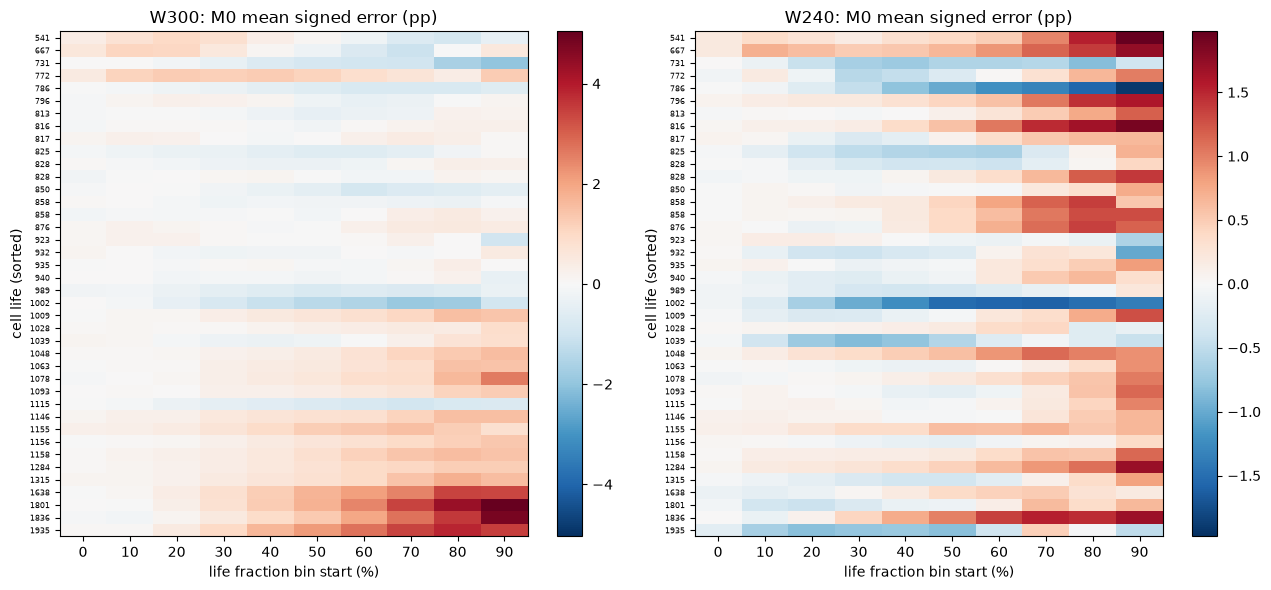

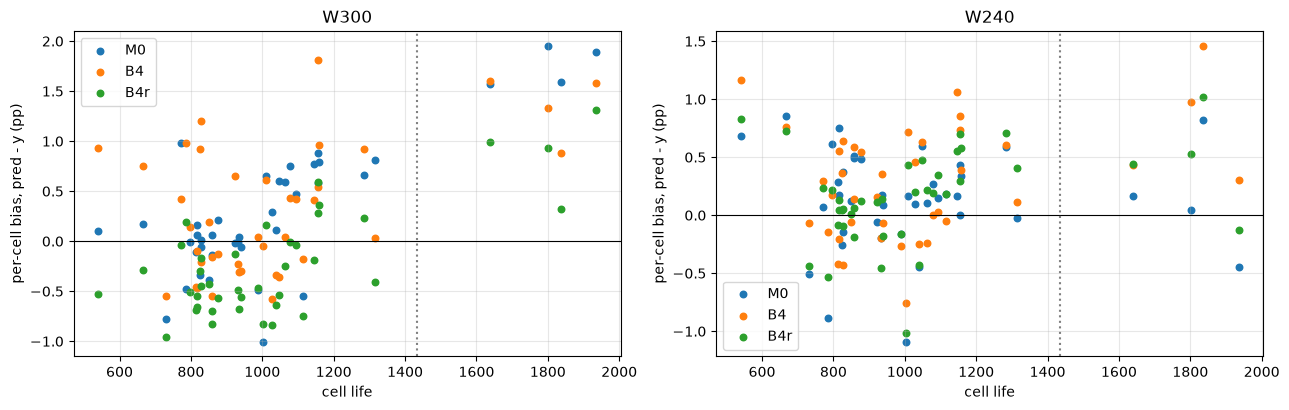

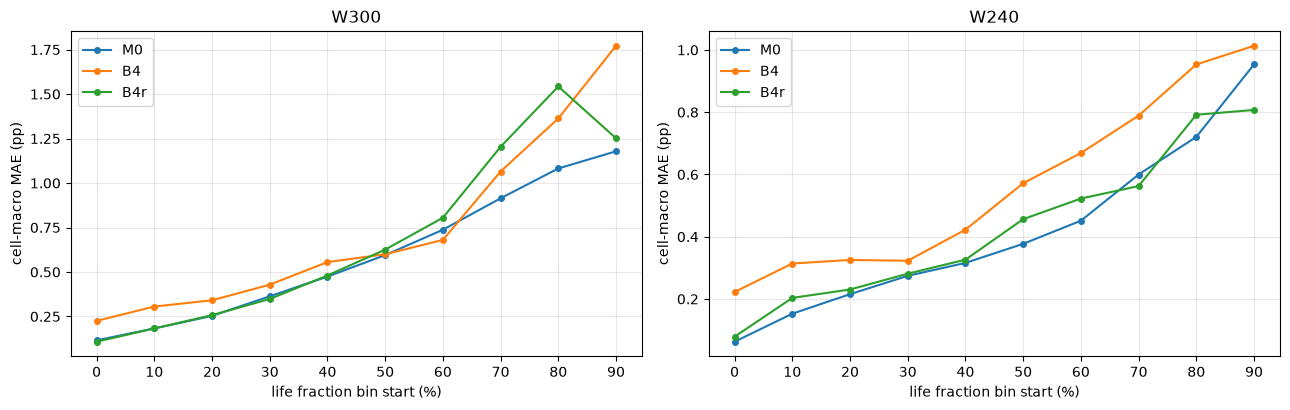

In [10]:
# S4 error anatomy
SPEC = [("M0", "M0"), ("B4", "B4"), ("B4r", "B4r"), ("M0idx", "M0+idx")]
def find_knees():
    for f in sorted((ROOT / "outputs/phase6a").rglob("*.csv")) + sorted((ROOT / "outputs/phase6a").rglob("*.parquet")):
        try: t = pd.read_csv(f) if f.suffix == ".csv" else pd.read_parquet(f)
        except Exception: continue
        kc = [c for c in t.columns if "knee" in c.lower()]
        if "cell_id" in t.columns and kc: return f, dict(zip(t.cell_id, t[kc[0]].astype(float))), kc[0]
    return None, {}, None
KF, KNEE6A, KCOL = find_knees()
def own_knee(cyc, y):
    o = np.argsort(cyc); c, yy = cyc[o], y[o]; best = (np.inf, c[len(c) // 2])
    for k in c[int(.1 * len(c)):int(.9 * len(c)):max(1, len(c) // 60)]:
        A = np.column_stack([np.ones_like(c), c, np.maximum(c - k, 0)]); sse = ((yy - A @ np.linalg.lstsq(A, yy, rcond=None)[0]) ** 2).sum()
        if sse < best[0]: best = (sse, k)
    return float(best[1])
KNEE, KSRC = {}, {}
for c in B3C:
    if c in KNEE6A:
        v = KNEE6A[c]; KNEE[c] = v * LIFE[c] if v <= 1.5 else v; KSRC[c] = "6a two-line fit"
    else:
        m = (B3T.cell_id == c).to_numpy(); KNEE[c] = own_knee(B3T.cycle.to_numpy()[m], B3T.y.to_numpy()[m]); KSRC[c] = "own two-line fit (descriptive)"
print("knee source:", f"{KF.relative_to(ROOT)} column '{KCOL}'" if KF else "no stored 6a knee table found", "|", pd.Series(KSRC).value_counts().to_dict())
check("knee available for every batch-3 cell", all(np.isfinite(list(KNEE.values()))), f"{sum(v == '6a two-line fit' for v in KSRC.values())} from 6a, {sum(v != '6a two-line fit' for v in KSRC.values())} own fit", warn_only=True)
B3T["knee"] = B3T.cell_id.map(KNEE); B3T["stage"] = np.where(B3T.last20, "last 20% of life", np.where(B3T.cycle < B3T.knee, "before knee", "after knee"))
S4A, S4GRP, S4FRAC, S4STAGE, S4SP, S4WORST, S4HEAT = [], [], [], [], [], [], {}
LG = [("life<=1000", lambda L: L <= 1000), ("1000<life<=1434", lambda L: (L > 1000) & (L <= 1434)), ("life>1434", lambda L: L > 1434)]
for w in WINDOWS:
    for m, nm in SPEC:
        e = PR[(m, w)] - Y_B3; d = pd.DataFrame(dict(cell_id=B3T.cell_id.values, e=e, ae=np.abs(e), se=e ** 2, frac=B3T.frac.values, stage=B3T.stage.values)); pc = PC[(m, w)]
        g = d.groupby("cell_id"); b = g.e.transform("mean"); orc = (d.e - b).abs().groupby(d.cell_id).mean().loc[B3C]
        share_pool = float((g.size() * pc.bias ** 2).sum() / d.se.sum()); share_macro = float((pc.bias ** 2 / g.se.mean().loc[B3C]).mean())
        S4A.append(dict(window=w, model=nm, cell_macro_mae=pc.mae.mean(), bias_share_pooled_sq_error=share_pool, bias_share_cell_mean=share_macro,
                        oracle_bias_removed_mae_DIAGNOSTIC_NONDEPLOYABLE=float(orc.mean()), n_cells=len(pc)))
        rho, p = stats.spearmanr(pc.life, pc.bias); idx = np.random.default_rng(SEED).integers(0, len(pc), (DRAWS, len(pc)))
        L_, B_ = pc.life.to_numpy()[idx], pc.bias.to_numpy()[idx]; rl, rb = stats.rankdata(L_, axis=1), stats.rankdata(B_, axis=1)
        rl, rb = rl - rl.mean(1, keepdims=True), rb - rb.mean(1, keepdims=True); rr = (rl * rb).sum(1) / np.sqrt((rl ** 2).sum(1) * (rb ** 2).sum(1)); rr = rr[np.isfinite(rr)]
        S4SP.append(dict(window=w, model=nm, spearman_bias_vs_life=float(rho), p_value=float(p), ci_lo=float(np.percentile(rr, 2.5)), ci_hi=float(np.percentile(rr, 97.5)), n_cells=len(pc), n_valid_draws=len(rr)))
        for gn_, fn in LG:
            sel = pc.index[fn(pc.life.to_numpy())]; S4GRP.append(dict(window=w, model=nm, life_group=gn_, n_cells=len(sel), mae=pc.loc[sel, "mae"].mean() if len(sel) else np.nan, bias=pc.loc[sel, "bias"].mean() if len(sel) else np.nan))
        bins = np.minimum((d.frac.to_numpy() * 10).astype(int), 9); fm = d.assign(bin=bins).groupby(["cell_id", "bin"]).agg(ae=("ae", "mean"), e=("e", "mean")).reset_index()
        for k, gg in fm.groupby("bin"): S4FRAC.append(dict(window=w, model=nm, life_fraction_bin=f"{k * 10}-{k * 10 + 10}%", n_cells=len(gg), mae=gg.ae.mean(), signed_error=gg.e.mean()))
        if m == "M0": S4HEAT[w] = fm.pivot(index="cell_id", columns="bin", values="e").reindex(sorted(B3C, key=lambda c: LIFE[c]))
        for stg, gg in d.groupby("stage"):
            S4STAGE.append(dict(window=w, model=nm, stage=stg, n_cells=gg.cell_id.nunique(), n_rows=len(gg), cell_macro_mae=gg.groupby("cell_id").ae.mean().mean()))
    pc = PC[("M0", w)].copy(); pc["shared_policy_with_dev"] = [c in SHARED_B3 for c in pc.index]; pc["life_above_1434"] = pc.life > 1434
    pc["offset_cell"] = (pc.bias.abs() >= 0.8 * pc.mae) & (pc.mae >= 1.0)
    S4WORST.append(pc.sort_values("mae", ascending=False).head(5).reset_index().rename(columns={"index": "cell_id"}).assign(window=w)[["window", "cell_id", "life", "mae", "bias", "life_above_1434", "shared_policy_with_dev", "offset_cell"]])
show(pd.DataFrame(S4A), "S4 bias-vs-noise split per model (oracle column is a diagnostic, non-deployable)", "s4_bias_noise.csv")
S4SPT = show(pd.DataFrame(S4SP), "S4 Spearman(per-cell bias, life) with cell-bootstrap 95% CI", "s4_spearman.csv")
show(pd.DataFrame(S4GRP), "S4 life-group tables", "s4_life_groups.csv")
show(pd.DataFrame(S4FRAC), "S4 error by life fraction (10 bins, cell-macro)", "s4_by_life_fraction.csv")
show(pd.DataFrame(S4STAGE), "S4 error by stage (before/after knee, last 20% of life)", "s4_by_stage.csv")
show(pd.concat(S4WORST), "S4 five worst cells by M0 (labels: life > 1434, shared policy with development, offset cell = |bias| >= 0.8 x MAE and MAE >= 1 pp)", "s4_worst_cells.csv")
print(f"development cells with life > 1,434 cycles: {N_DEV_LONG} of {len(DEV_CELLS)}; batch-3 cells above 1,434: {int(LONG(B3C).sum())} of {len(B3C)}")
# figures
fig, axs = plt.subplots(1, 2, figsize=(13, 6))
for ax, w in zip(axs, WINDOWS):
    H = S4HEAT[w]; v = np.nanmax(np.abs(H.to_numpy())) or 1; im = ax.imshow(H.to_numpy(), aspect="auto", cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_yticks(range(len(H))); ax.set_yticklabels([f"{LIFE[c]:.0f}" for c in H.index], fontsize=6); ax.set_xticks(range(10)); ax.set_xticklabels([f"{k * 10}" for k in range(10)])
    ax.set_xlabel("life fraction bin start (%)"); ax.set_ylabel("cell life (sorted)"); ax.set_title(f"{w}: M0 mean signed error (pp)"); plt.colorbar(im, ax=ax)
fig.tight_layout(); fig.savefig(W(OUT / "fig_heatmap_error_by_life.png"), dpi=130); plt.show()
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, w in zip(axs, WINDOWS):
    for m, nm in SPEC[:3]: ax.scatter([LIFE[c] for c in B3C], PC[(m, w)].bias, s=22, label=nm)
    ax.axhline(0, color="k", lw=.8); ax.axvline(1434, color="grey", ls=":"); ax.set_xlabel("cell life"); ax.set_ylabel("per-cell bias, pred - y (pp)"); ax.set_title(w); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(W(OUT / "fig_bias_vs_life.png"), dpi=130); plt.show()
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2)); FR = pd.DataFrame(S4FRAC)
for ax, w in zip(axs, WINDOWS):
    for m, nm in SPEC[:3]:
        t = FR[(FR.window == w) & (FR.model == nm)]; ax.plot(range(len(t)), t.mae, "o-", ms=4, label=nm)
    ax.set_xticks(range(10)); ax.set_xticklabels([f"{k * 10}" for k in range(10)]); ax.set_xlabel("life fraction bin start (%)"); ax.set_ylabel("cell-macro MAE (pp)"); ax.set_title(w); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(W(OUT / "fig_error_vs_life_fraction.png"), dpi=130); plt.show()

In [11]:
# S5 alerts and interval coverage with the frozen configuration
def alerts(df, sig, thr, keys):
    rows = []; cyc, yv, lf = df.cycle.to_numpy(), df.y.to_numpy(), df.life.to_numpy()
    for k, ix in df.groupby(keys, sort=False).indices.items():
        cr = np.flatnonzero(yv[ix] <= thr + 1e-9); fi = np.flatnonzero(sig[ix] <= thr)
        rows.append(dict(key=k, life=lf[ix][0], cross=cyc[ix][cr[0]] if len(cr) else np.nan, fire=cyc[ix][fi[0]] if len(fi) else np.nan))
    return pd.DataFrame(rows)
def alert_summary(a):
    c = a[a.cross.notna()]; n = len(c); miss = c.fire.isna(); det = c[~miss]; dl = det.fire - det.cross; pct = 100 * dl / det.life
    early = det.fire < det.cross - 0.05 * det.life
    return dict(n_cells=len(a), n_with_crossing=n, n_detected=len(det), missed_pct=100 * miss.mean() if n else np.nan, early_pct=100 * early.sum() / n if n else np.nan,
                median_abs_delay_cycles=dl.abs().median(), mean_abs_delay_cycles=dl.abs().mean(), median_abs_delay_pct_life=pct.abs().median(), mean_abs_delay_pct_life=pct.abs().mean(),
                median_signed_delay_pct_life=pct.median())
def series_for(w, kind):
    p = PR[("M0", w)]
    if kind == "raw": return p
    out = np.empty(len(p)); a = ALPHA[w]
    for _, ix in B3T.groupby("cell_id", sort=False).indices.items(): out[ix] = lfilter([a], [1, -(1 - a)], p[ix], zi=[(1 - a) * p[ix][0]])[0]
    return out
S5, S5COV, B3SER = [], [], {}
for w in WINDOWS:
    for kind in ("raw", "ema"):
        est = series_for(w, kind); B3SER[(w, kind)] = est; lo2, hi2, lowb, q2 = conf_apply(CONF[w][kind], est)
        for thr, rule, sig in ((85.0, "A: estimate <= 85", est), (80.0, "A: estimate <= 80", est), (80.0, "B: lower bound <= 80", lowb)):
            s = alert_summary(alerts(B3T, sig, thr, "cell_id")); S5.append(dict(window=w, series=kind, alert="85% warning" if thr == 85 else "80% EOL", rule=rule, **s))
S5T = show(pd.DataFrame(S5), "S5 batch-3 alert metrics (M0 ensemble mean; frozen config). missed = never fires by EOL; early = fires > 5% of life before true crossing", "s5_alerts_batch3.csv")
REF6B = pd.DataFrame([dict(window="W300", alert="85% rule A", missed_pct=1.3, early_pct=3.8, mean_abs_delay_pct_life=2.4), dict(window="W240", alert="85% rule A", missed_pct=1.3, early_pct=0.0, mean_abs_delay_pct_life=1.2),
                      dict(window="W300", alert="80% EOL rule A", missed_pct=63.7, early_pct=1.3, mean_abs_delay_pct_life=1.4), dict(window="W300", alert="80% EOL rule B", missed_pct=7.2, early_pct=30.0, mean_abs_delay_pct_life=4.4),
                      dict(window="W240", alert="80% EOL rule A", missed_pct=52.3, early_pct=0.0, mean_abs_delay_pct_life=0.5), dict(window="W240", alert="80% EOL rule B", missed_pct=7.6, early_pct=0.8, mean_abs_delay_pct_life=2.2)])
show(REF6B, "Development reference from 6b (non-stitched cells, M0 raw; as given)", "s5_dev_reference_6b.csv", 1)
DREF = []
for w in WINDOWS:
    d = DEV[w][~DEV[w].stitched].reset_index(drop=True); lo2, hi2, lowb, _ = conf_apply(CONF[w]["raw"], d.pred.to_numpy())
    for thr, rule, sig in ((85.0, "85% rule A", d.pred.to_numpy()), (80.0, "80% EOL rule A", d.pred.to_numpy()), (80.0, "80% EOL rule B", lowb)):
        DREF.append(dict(window=w, alert=rule, **alert_summary(alerts(d, sig, thr, ["repeat", "cell_id"]))))
show(pd.DataFrame(DREF), f"Recomputed development OOF reference, non-stitched cells x 3 repeats (in-sample conformal; compare with 6b table above)", "s5_dev_recomputed.csv", 2)
for w in WINDOWS:
    for kind in ("raw", "ema"):
        est = B3SER[(w, kind)]; y = B3T.y.to_numpy()
        for variant in ("pooled", "cellbal"):
            lo2, hi2, lowb, q2 = conf_apply(CONF[w][kind], est, variant); ins = (y >= lo2) & (y <= hi2); below, above = y < lo2, y > hi2
            cc = pd.Series(ins.astype(float)).groupby(B3T.cell_id.values).mean().loc[B3C]; pt, cl, ch = boot(cc.to_numpy()); lc = pd.Series((y >= lowb).astype(float)).groupby(B3T.cell_id.values).mean().loc[B3C]
            lg_ = {}
            for gn_, fn in LG:
                msk = np.array([bool(fn(LIFE[c])) for c in B3C]); lg_[gn_] = float(cc[msk].mean()) if msk.any() else np.nan
            miss = ~ins; longrow = (B3T.life > 1434).to_numpy()
            S5COV.append(dict(window=w, series=kind, variant=variant, macro_coverage=pt, macro_ci_lo=cl, macro_ci_hi=ch, pooled_coverage=float(ins.mean()), **{f"macro_cov | {k}": v for k, v in lg_.items()},
                              mean_width_pp=float((2 * q2).mean()), share_cells_cov_below_0_8=float((cc < 0.8).mean()), misses_y_below_lower=int(below.sum()), misses_y_above_upper=int(above.sum()),
                              share_of_misses_from_life_gt_1434=float(longrow[miss].mean()) if miss.any() else np.nan, share_of_rows_from_life_gt_1434=float(longrow.mean()),
                              lower_bound_macro_coverage=float(lc.mean()), n_cells=len(cc), n_rows=len(y)))
S5CT = show(pd.DataFrame(S5COV), "S5 interval coverage on batch 3 (two-sided 90%; lower_bound_macro_coverage is the one-sided rule-B bound). Under-coverage is a finding, not an error", "s5_coverage_batch3.csv", 3)


S5 batch-3 alert metrics (M0 ensemble mean; frozen config). missed = never fires by EOL; early = fires > 5% of life before true crossing  (n=12 rows)
window series       alert                 rule  n_cells  n_with_crossing  n_detected  missed_pct  early_pct  median_abs_delay_cycles  mean_abs_delay_cycles  median_abs_delay_pct_life  mean_abs_delay_pct_life  median_signed_delay_pct_life
  W300    raw 85% warning    A: estimate <= 85       40               40          40       0.000      2.500                   11.500                 17.925                      1.094                    1.552                         0.122
  W300    raw     80% EOL    A: estimate <= 80       40                0           0         NaN        NaN                      NaN                    NaN                        NaN                      NaN                           NaN
  W300    raw     80% EOL B: lower bound <= 80       40                0           0         NaN        NaN                      NaN   

In [12]:
# S6 secondary lines (descriptive, not selected)
S6 = []
for w in WINDOWS:
    allm = pd.Series({LAB[m]: PC[(m, w)].mae.mean() for m in LAB}).rank(method="min")
    for m in ("M0idx", "B4r", "B4ridx", "AVG", "B3r"):
        pc = PC[(m, w)]; S6.append(dict(window=w, model=LAB[m], cell_macro_mae=pc.mae.mean(), mae_last20=pc.mae_last20.mean(), bias=pc.bias.mean(), rank_of_10_lines=int(allm[LAB[m]]), n_cells=len(pc)))
show(pd.DataFrame(S6), "S6 secondary lines on batch 3 (rank among all 10 lines by cell-macro MAE; descriptive only)", "s6_secondary_lines.csv")
print("Batch 3 is spent: these numbers describe the test set and select nothing (no model, window, alpha, quantile or threshold is chosen on them).")


S6 secondary lines on batch 3 (rank among all 10 lines by cell-macro MAE; descriptive only)  (n=10 rows)
window       model  cell_macro_mae  mae_last20   bias  rank_of_10_lines  n_cells
  W300      M0+idx           0.641       1.078 -0.265                 4       40
  W300         B4r           0.692       1.398 -0.227                 5       40
  W300     B4r+idx           0.534       1.069 -0.209                 1       40
  W300 avg(M0,B4r)           0.544       1.094  0.041                 2       40
  W300         B3r           1.950       4.729  1.938                 8       40
  W240      M0+idx           0.546       0.924 -0.390                 5       40
  W240         B4r           0.433       0.800  0.158                 4       40
  W240     B4r+idx           0.333       0.513 -0.008                 1       40
  W240 avg(M0,B4r)           0.394       0.786  0.149                 2       40
  W240         B3r           0.766       1.692  0.613                 7       40
Bat

In [13]:
# S7 expectations versus observation
def row(h, exp, obs, ok): return dict(id=h, expected=exp, observed=obs, consistent=ok)
S7 = []
a = S3AT.set_index("window")
S7.append(row("H1", "cluster CI wider than cell CI at both windows", "; ".join(f"{w}: cluster {a.loc[w, 'cluster_width']:.3f} vs cell {a.loc[w, 'cell_width']:.3f} pp, includes zero {bool(a.loc[w, 'cluster_includes_zero'])}" for w in WINDOWS),
              bool(all(a.loc[w, "cluster_width"] > a.loc[w, "cell_width"] for w in WINDOWS))))
c = S5CT[(S5CT.series == "raw") & (S5CT.variant == "pooled")].set_index("window")
S7.append(row("H2", "macro coverage >= 0.90 at both windows, misses concentrated in life > 1434", "; ".join(f"{w}: coverage {c.loc[w, 'macro_coverage']:.3f}, {100 * c.loc[w, 'share_of_misses_from_life_gt_1434']:.0f}% of misses from long cells vs {100 * c.loc[w, 'share_of_rows_from_life_gt_1434']:.0f}% of rows" for w in WINDOWS),
              bool(all(c.loc[w, "macro_coverage"] >= 0.90 and c.loc[w, "share_of_misses_from_life_gt_1434"] > c.loc[w, "share_of_rows_from_life_gt_1434"] for w in WINDOWS))))
s = S5T[(S5T.alert == "85% warning") & (S5T.rule == "A: estimate <= 85")]
S7.append(row("H3", "median signed delay within +/-3% of life", "; ".join(f"{r.window}/{r.series}: {r.median_signed_delay_pct_life:+.2f}%" for r in s.itertuples()), bool((s.median_signed_delay_pct_life.abs() <= 3).all())))
sp = S4SPT[S4SPT.model == "M0"].set_index("window")
S7.append(row("H4", "positive and significant at W300, not significant at W240", "; ".join(f"{w}: rho {sp.loc[w, 'spearman_bias_vs_life']:+.3f} (p={sp.loc[w, 'p_value']:.3f}, CI {sp.loc[w, 'ci_lo']:+.2f} to {sp.loc[w, 'ci_hi']:+.2f})" for w in WINDOWS),
              bool(sp.loc["W300", "spearman_bias_vs_life"] > 0 and sp.loc["W300", "p_value"] < 0.05 and sp.loc["W240", "p_value"] >= 0.05)))
S7T = show(pd.DataFrame(S7), "S7 expectations (fixed before labels) vs observed; nothing is selected on this", "s7_expectations.csv")


S7 expectations (fixed before labels) vs observed; nothing is selected on this  (n=4 rows)
id                                                                   expected                                                                                                                               observed  consistent
H1                              cluster CI wider than cell CI at both windows                    W300: cluster 0.266 vs cell 0.256 pp, includes zero True; W240: cluster 0.184 vs cell 0.172 pp, includes zero False        True
H2 macro coverage >= 0.90 at both windows, misses concentrated in life > 1434 W300: coverage 0.986, 96% of misses from long cells vs 18% of rows; W240: coverage 0.980, 35% of misses from long cells vs 18% of rows        True
H3                                   median signed delay within +/-3% of life                                                                 W300/raw: +0.12%; W300/ema: +0.46%; W240/raw: +1.04%; W240/ema: +1.22%        True
H4      

In [14]:
# S8 report and artifacts
HASHES_END = verify_frozen("end")
check("monitor_config.json unchanged", sha256_file(CFG_PATH) == CFG_SHA, f"sha256 {CFG_SHA[:16]}...")
check("expectations file unchanged", sha256_file(EXP_PATH) == EXP_SHA, f"sha256 {EXP_SHA[:16]}...")
_ev = log_entries(); _lines = _log_lines()
check("phase7b log: hash chain intact", all(_ev[i]["prev_line_sha256"] == (sha256_bytes(_lines[i - 1].encode("utf-8")) if i else "") for i in range(len(_ev))), f"{len(_ev)} events {[e['event'] for e in _ev]}")
_names = [e["event"] for e in _ev]; _cf = _names.index("config_frozen")
check("config_frozen logged before the last labels_loaded", max(i for i, n in enumerate(_names) if n == "labels_loaded") > _cf, f"event order {_names}")
log_append("done", elapsed_s=round(time.time() - T0, 1), monitor_config_sha256=CFG_SHA)
for nm, df in TABLES.items(): df.to_csv(W(OUT / nm), index=False)
def tx(df, nd=3): return df.to_string(index=False, float_format=lambda v: f"{v:.{nd}f}")
Rp = ["PHASE 7b - BATCH-3 SECONDARY ANALYSIS AND MONITOR CONFIGURATION" + (" (SMOKE RUN - DO NOT QUOTE)" if SMOKE else ""), "=" * 78, "",
      "Batch 3 is spent; every batch-3 number below is descriptive. The monitor config was frozen from development data only before labels were read.", f"monitor_config.json sha256 {CFG_SHA}", "",
      f"EMA alpha chosen on development data: {ALPHA}", "Conformal bins: " + json.dumps(BIN_SRC), "Parity gate (dev macro coverage vs 6b): " + json.dumps(PARITY), "", "S2 GATE REPRODUCTION", tx(S2T), "",
      "S3a POLICY-CLUSTER BOOTSTRAP", tx(S3AT), "", "S3b WINS / TRIMMED", tx(S3BT), "", "S4 SPEARMAN", tx(S4SPT), "", "S5 ALERTS", tx(S5T, 2), "", "S5 COVERAGE", tx(S5CT), "",
      "S7 EXPECTED VS OBSERVED", tx(S7T), "", "CHECKS", "-" * 78] + [f"[{c['status']}] {c['name']} - {c['detail']}" for c in CHECKS]
write_text(OUT / "phase7b_report.txt", "\n".join(Rp) + "\n")
EXTRA.update(dict(hashes_start=HASHES_START, hashes_end=HASHES_END, monitor_config_sha256=CFG_SHA, expectations_sha256=EXP_SHA, label_reads=LABEL_LOG, alpha=ALPHA, parity=PARITY,
                  s7=S7, dev_cells_life_gt_1434=N_DEV_LONG, shared_policy_cells=SHARED_B3))
_n = dump_report()
arts = pd.DataFrame([dict(path=str(p.relative_to(ROOT)), size_kb=round(p.stat().st_size / 1024, 1)) for p in sorted(OUT.rglob("*")) if p.is_file()])
show(arts, "Artifacts", None, 1)
print(f"\nPASS {_n['PASS']} | WARN {_n['WARN']} | FAIL {_n['FAIL']} | runtime {(time.time() - T0) / 60:.1f} min" + (" | SMOKE: do not quote" if SMOKE else ""))

[PASS] [end] sha256 gate_week2 - week2_gate.json: got 40df2fb82096e994... expected 40df2fb82096e994...
[PASS] [end] sha256 soh_deep_v2 - soh_deep_v2.py: got fc53e37d506ebe51... expected fc53e37d506ebe51...
[PASS] [end] sha256 soh_deep_v3 - soh_deep_v3.py: got 9c022dd391193de9... expected 9c022dd391193de9...
[PASS] [end] sha256 soh_deep_v4 - soh_deep_v4.py: got 2be9ce5ded197b16... expected 2be9ce5ded197b16...
[PASS] [end] sha256 gate_verdict_5b - gate_verdict.json: got 2f59f82a7c7d8940... expected 2f59f82a7c7d8940...
[PASS] [end] sha256 frozen_config - frozen_config.json: got 78b571c7526551c7... expected 78b571c7526551c7...
[PASS] [end] sha256 preregistration - preregistration.json: got 11f9741387cb001e... expected 11f9741387cb001e...
[PASS] [end] sha256 batch3_predictions - batch3_predictions.parquet: got 679ec76862de63f2... expected 679ec76862de63f2...
[PASS] [end] sha256 batch3_verdict - batch3_verdict.json: got 57a054bdf25243d3... expected 57a054bdf25243d3...
[PASS] [end] sha256 for